In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
dataframe = pd.read_csv("df_corridas.csv")

In [8]:
dataframe['data'] = pd.to_datetime(dataframe['data'], errors='coerce', utc=True)

df_corridas = dataframe[
    (dataframe["data"].dt.year == 2026) & (dataframe["distancia_km"] >= 2.0) & (dataframe["pace_dec"] <8)
].copy()


df_corridas["faixa_distancia"] = pd.cut(
    df_corridas["distancia_km"],
    bins=[2.00, 4.89, 5.4, 5.9, 6.3, 6.9, 7.3, 7.9, 8.3, 9.8, 10.3, 50],
    labels=[
        "2.0_4.89",
        "Base 5K",
        "5-6",
        "Base 6K",
        "6-7",
        "Base 7K",
        "7-8",
        "Base 8K",
        "8-10",
        "Base 10K",
        "+10",
    ],
)

df_corridas["mes"] = df_corridas["data"].dt.to_period("M")

df_corridas["horario"] = df_corridas["data"].dt.strftime("%H:%M")

C:\Users\batat\AppData\Local\Temp\ipykernel_26468\1195286088.py:26: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_corridas["mes"] = df_corridas["data"].dt.to_period("M")


In [9]:
# Tabela cruzada mostrando sua evolução de volume mês a mês
resumo_mensal = pd.crosstab(df_corridas["mes"], df_corridas["faixa_distancia"], margins=True)
print("--- Evolução de Distância por Mês (2026) ---")
print(resumo_mensal)

--- Evolução de Distância por Mês (2026) ---
faixa_distancia  2.0_4.89  Base 5K  5-6  Base 6K  6-7  Base 7K  7-8  Base 8K  \
mes                                                                            
2026-01                 3        2    1        0    0        0    0        0   
2026-02                 1        0    1        0    0        0    0        0   
2026-03                 3        6    0        0    0        0    0        0   
2026-04                 3        8    0        1    0        2    0        2   
2026-05                 0        8    0        2    0        6    0        3   
2026-06                 1        9    0        2    0        3    2        1   
2026-07                 1        2    0        5    1        3    0        2   
2026-08                 0        3    0        6    0        5    0        2   
2026-09                 4        1    0        1    1        6    1        0   
2026-10                 3        0    0        2    0        2    0        

In [10]:
df5km = df_corridas[df_corridas['faixa_distancia'] == 'Base 5K'].copy()

df5km = df5km.sort_values(by="pace_dec", ascending=True)



display(df5km.head())

,record_id,data,modalidade,distancia_km,duracao_min,duracao_fmt,pace_dec,pace_fmt,bpm_medio,bpm_max,...,cadencia_media,ganho_elev_total_m,perda_elev_total_m,kcal,te_aerobico,te_anaerobico,tem_splits_oficiais,faixa_distancia,mes,horario
208,vrh+DwAAAAACAAAAYASkc6ABAAA=,2026-09-05 19:15:24.000+00:00,Rua,5.38,24.62,24:37,4.58,4:35,185,191,...,180,52.7,-55.1,369.0,3.0,4.5,True,Base 5K,2026-09,19:15
191,vrh+DwAAAAACAAAASA0M6Z8BAAA=,2026-08-09 21:21:49.000+00:00,Rua,5.00,23.63,23:38,4.73,4:44,167,184,...,175,44.8,-49.3,319.0,2.8,2.3,True,Base 5K,2026-08,21:21
171,vrh+DwAAAAACAAAAgB93OZ8BAAA=,2026-07-06 19:05:36.000+00:00,Rua,5.01,24.27,24:16,4.84,4:50,177,193,...,173,34.4,-37.9,328.0,2.9,3.8,True,Base 5K,2026-07,19:05
115,bFAkEgAAAAACAAAAfhfQdp0BAAA=,2026-04-10 06:54:02.238+00:00,Rua,4.90,25.24,25:14,5.15,5:09,134,159,...,25,0.0,0.0,435.0,1.4,0.0,True,Base 5K,2026-04,06:54
153,vrh+DwAAAAACAAAAoKliqZ4BAAA=,2026-06-08 19:37:56.000+00:00,Rua,5.00,26.15,26:09,5.23,5:14,163,183,...,175,79.6,-96.0,321.0,2.7,1.8,True,Base 5K,2026-06,19:37


In [ ]:
df5km.columns

Index(['record_id', 'data', 'modalidade', 'distancia_km', 'duracao_min',
       'duracao_fmt', 'pace_dec', 'pace_fmt', 'bpm_min', 'bpm_medio',
       'bpm_max', 'deriva_cardiaca', 'pct_tempo_bpm_165+', 'cadencia_min',
       'cadencia_media', 'cadencia_max', 'altitude_min_m', 'altitude_media_m',
       'altitude_max_m', 'ganho_elev_total_m', 'perda_elev_total_m', 'kcal',
       'te_aerobico', 'te_anaerobico', 'tem_splits_oficiais',
       'faixa_distancia', 'horario'],
      dtype='str')

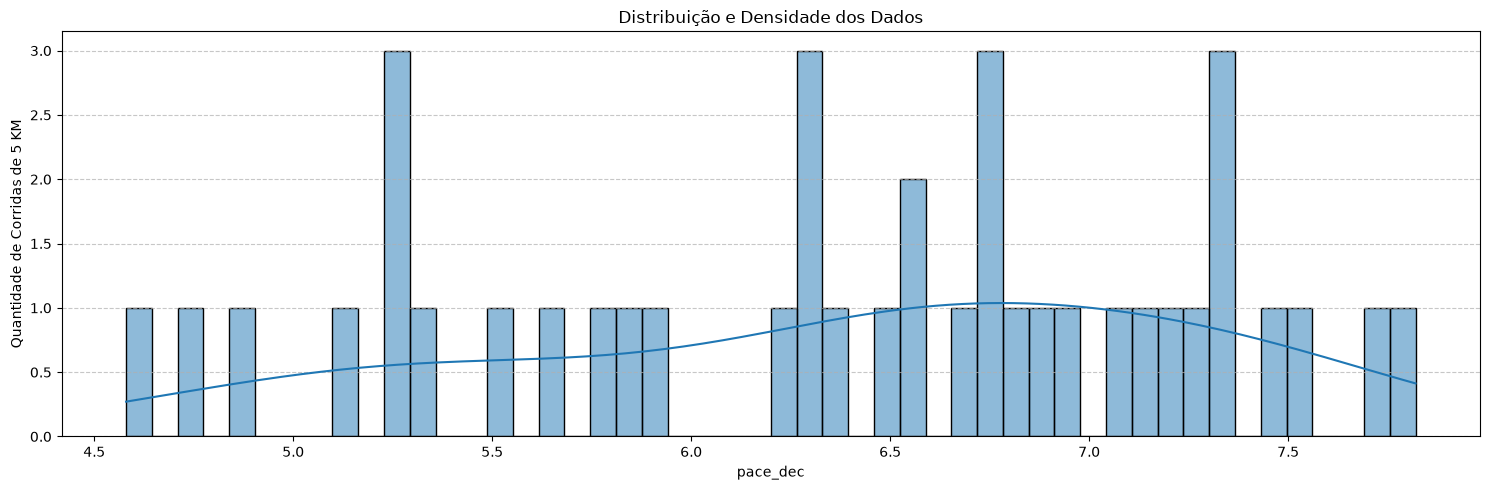

In [ ]:
plt.figure(figsize=(15, 5))
sns.histplot(df5km['pace_dec'], kde=True, color='#1f77b4', bins=50)
plt.title("Distribuição e Densidade dos Dados")
plt.ylabel("Quantidade de Corridas de 5 KM")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

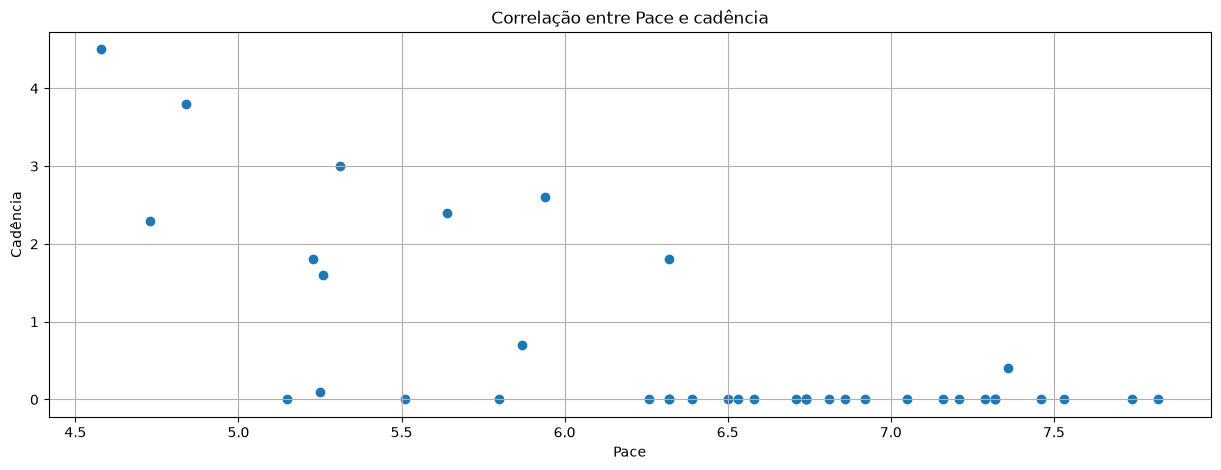

In [ ]:
plt.figure(figsize=(15, 5))

plt.xlabel('Pace')
plt.ylabel('Cadência')
plt.title('Correlação entre Pace e cadência')
plt.scatter(df5km['pace_dec'], df5km['te_anaerobico'])
plt.grid(True)
plt.show()

In [ ]:
display(df5km)

,record_id,data,modalidade,distancia_km,duracao_min,duracao_fmt,pace_dec,pace_fmt,bpm_min,bpm_medio,...,altitude_media_m,altitude_max_m,ganho_elev_total_m,perda_elev_total_m,kcal,te_aerobico,te_anaerobico,tem_splits_oficiais,faixa_distancia,horario
208,vrh+DwAAAAACAAAAYASkc6ABAAA=,2026-09-05 19:15:24.000+00:00,Rua,5.38,24.62,24:37,4.58,4:35,140.0,185,...,610.4,6.264000e+02,52.7,-55.1,369.0,3.0,4.5,True,Base 5K,19:15
191,vrh+DwAAAAACAAAASA0M6Z8BAAA=,2026-08-09 21:21:49.000+00:00,Rua,5.00,23.63,23:38,4.73,4:44,84.0,167,...,613.2,6.210000e+02,44.8,-49.3,319.0,2.8,2.3,True,Base 5K,21:21
171,vrh+DwAAAAACAAAAgB93OZ8BAAA=,2026-07-06 19:05:36.000+00:00,Rua,5.01,24.27,24:16,4.84,4:50,79.0,177,...,613.4,6.217000e+02,34.4,-37.9,328.0,2.9,3.8,True,Base 5K,19:05
115,bFAkEgAAAAACAAAAfhfQdp0BAAA=,2026-04-10 06:54:02.238+00:00,Rua,4.90,25.24,25:14,5.15,5:09,96.0,134,...,NaN,1.400000e-45,0.0,0.0,435.0,1.4,0.0,True,Base 5K,06:54
153,vrh+DwAAAAACAAAAoKliqZ4BAAA=,2026-06-08 19:37:56.000+00:00,Rua,5.00,26.15,26:09,5.23,5:14,79.0,163,...,608.6,6.235000e+02,79.6,-96.0,321.0,2.7,1.8,True,Base 5K,19:37
187,vrh+DwAAAAACAAAAWIs+v58BAAA=,2026-08-01 18:32:55.000+00:00,Rua,5.01,26.30,26:18,5.25,5:15,86.0,156,...,612.9,6.268000e+02,67.4,-68.4,322.0,2.5,0.1,True,Base 5K,18:32
162,vrh+DwAAAAACAAAAWErl5p4BAAA=,2026-06-20 18:17:27.000+00:00,Rua,5.13,26.97,26:58,5.26,5:16,83.0,162,...,610.6,6.260000e+02,83.2,-100.2,328.0,2.8,1.6,True,Base 5K,18:17
142,vrh+DwAAAAACAAAAyOyKXJ4BAAA=,2026-05-24 21:31:09.000+00:00,Rua,5.00,26.55,26:33,5.31,5:19,87.0,172,...,628.8,6.422000e+02,62.3,-76.0,346.0,3.0,3.0,True,Base 5K,21:31
192,vrh+DwAAAAACAAAAONW98p8BAAA=,2026-08-11 18:32:35.000+00:00,Rua,5.00,27.57,27:34,5.51,5:31,77.0,147,...,631.7,6.587000e+02,90.6,-88.0,316.0,2.1,0.0,True,Base 5K,18:32
132,vrh+DwAAAAACAAAAGGXUCZ4BAAA=,2026-05-08 20:02:55.000+00:00,Rua,5.01,28.23,28:14,5.64,5:38,85.0,168,...,607.1,6.226000e+02,79.7,-92.7,361.0,3.0,2.4,True,Base 5K,20:02


In [ ]:
df5km = df5km.sort_values(by="data", ascending=False)
#df5km["mes"] = df5km["data"].dt.to_period("M").unique()

plt.plot(df5km['mes'], df5km['pace_dec'], marker="o")

plt.xlabel("Ano")
plt.ylabel("Receita (em bilhões de dólares)")
plt.title("Evolução anual da receita da Apple")

plt.grid()
plt.show()


C:\Users\batat\AppData\Local\Temp\ipykernel_5840\3794049125.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df5km["mes"] = df5km["data"].dt.to_period("M").unique()


ValueError: Length of values (8) does not match length of index (39)

In [ ]:
cores = plt.get_cmap('Set3').colors
ciclo_cores = cycler("color", cores)
plt.rc("axes", prop_cycle=ciclo_cores)


plt.figure(figsize=(11, 6))

barras = plt.bar(ano, receita)
#plt.bar_label(barras, labels=receita, padding=5, fontsize=7, fontweight='bold')
plt.bar_label(barras)

plt.xticks(ano, rotation=45)

plt.xlabel("Ano")
plt.ylabel("Receita (em bilhões de dólares)")
plt.title("Evolução anual da receita da Apple")

plt.show()

NameError: name 'cycler' is not defined

In [ ]:
cores = plt.get_cmap('Set1').colors
ciclo_cores = cycler("color", cores)
plt.rc("axes", prop_cycle=ciclo_cores)

plt.scatter(ano, receita, s=receita, c=receita, cmap="Reds")

plt.grid(True, linestyle='dotted')

plt.xlabel("Ano")
plt.ylabel("Receita (em bilhões de dólares)")
plt.title("Evolução anual da receita da Apple")

plt.colorbar()

plt.show()

In [ ]:
df6km = df[df['faixa_distancia'] == 'Base 6K'].copy()

df6km = df6km.sort_values(by="pace_dec", ascending=True)

display(df6km)

,record_id,data,modalidade,distancia_km,duracao_min,duracao_fmt,pace_dec,pace_fmt,bpm_min,bpm_medio,...,altitude_min_m,altitude_media_m,altitude_max_m,ganho_elev_total_m,perda_elev_total_m,kcal,te_aerobico,te_anaerobico,tem_splits_oficiais,faixa_distancia
200,vrh+DwAAAAACAAAAAEsANqABAAA=,2026-08-24 19:59:44+00:00,Rua,6.00,29.45,29:27,4.91,4:55,82.0,130,...,621.2,627.2,635.9,54.5,-60.1,334.0,1.2,0.0,True,Base 6K
181,vrh+DwAAAAACAAAAgG3vi58BAAA=,2026-07-22 19:25:52+00:00,Rua,6.00,29.95,29:57,4.99,4:59,87.0,164,...,594.1,612.2,623.1,62.4,-83.0,385.0,3.0,0.7,True,Base 6K
190,vrh+DwAAAAACAAAA2Aoq2Z8BAAA=,2026-08-06 19:20:39+00:00,Rua,6.00,30.42,30:25,5.07,5:04,106.0,166,...,589.4,608.3,619.4,59.9,-81.1,397.0,3.0,1.9,True,Base 6K
198,vrh+DwAAAAACAAAA0GR7IaABAAA=,2026-08-20 20:22:10+00:00,Rua,6.00,34.20,34:12,5.70,5:42,83.0,152,...,591.3,611.1,636.0,79.5,-85.8,399.0,2.7,0.0,True,Base 6K
228,vrh+DwAAAAACAAAA6L+VVqEBAAA=,2026-10-19 20:53:37+00:00,Rua,6.00,35.47,35:28,5.91,5:55,88.0,160,...,606.2,632.1,654.7,101.1,-99.7,454.0,3.0,0.5,True,Base 6K
177,vrh+DwAAAAACAAAAMBEGbZ8BAAA=,2026-07-16 19:22:22+00:00,Rua,6.23,37.32,37:19,5.99,5:59,79.0,148,...,596.8,620.0,642.8,79.4,-95.1,407.0,2.6,0.0,True,Base 6K
193,vrh+DwAAAAACAAAAGO72958BAAA=,2026-08-12 18:53:03+00:00,Rua,6.03,36.82,36:49,6.11,6:07,79.0,149,...,594.4,615.2,640.5,90.2,-106.3,407.0,2.6,0.0,True,Base 6K
195,vrh+DwAAAAACAAAA2FOKAqABAAA=,2026-08-14 20:10:15+00:00,Rua,6.00,37.22,37:13,6.20,6:12,76.0,140,...,609.5,630.6,655.7,74.2,-91.0,391.0,2.1,0.0,True,Base 6K
179,vrh+DwAAAAACAAAA2DHdhp8BAAA=,2026-07-21 19:47:51+00:00,Rua,6.02,37.67,37:40,6.26,6:16,97.0,149,...,586.3,611.6,630.4,103.6,-124.2,403.0,2.6,0.0,True,Base 6K
169,vrh+DwAAAAACAAAA0HnmH58BAAA=,2026-07-01 19:57:06+00:00,Rua,6.00,38.02,38:01,6.34,6:20,87.0,145,...,597.0,618.4,643.5,92.4,-107.1,393.0,2.4,0.0,True,Base 6K


In [ ]:
display(df5km)

,record_id,data,modalidade,distancia_km,duracao_min,duracao_fmt,pace_dec,pace_fmt,bpm_min,bpm_medio,...,altitude_min_m,altitude_media_m,altitude_max_m,ganho_elev_total_m,perda_elev_total_m,kcal,te_aerobico,te_anaerobico,tem_splits_oficiais,faixa_distancia
208,vrh+DwAAAAACAAAAYASkc6ABAAA=,2026-09-05 19:15:24.000+00:00,Rua,5.38,24.62,24:37,4.58,4:35,140.0,185,...,5.968000e+02,610.4,6.264000e+02,52.7,-55.1,369.0,3.0,4.5,True,Base 5K
191,vrh+DwAAAAACAAAASA0M6Z8BAAA=,2026-08-09 21:21:49.000+00:00,Rua,5.00,23.63,23:38,4.73,4:44,84.0,167,...,6.066000e+02,613.2,6.210000e+02,44.8,-49.3,319.0,2.8,2.3,True,Base 5K
171,vrh+DwAAAAACAAAAgB93OZ8BAAA=,2026-07-06 19:05:36.000+00:00,Rua,5.01,24.27,24:16,4.84,4:50,79.0,177,...,6.074000e+02,613.4,6.217000e+02,34.4,-37.9,328.0,2.9,3.8,True,Base 5K
115,bFAkEgAAAAACAAAAfhfQdp0BAAA=,2026-04-10 06:54:02.238+00:00,Rua,4.90,25.24,25:14,5.15,5:09,96.0,134,...,3.402823e+38,NaN,1.400000e-45,0.0,0.0,435.0,1.4,0.0,True,Base 5K
153,vrh+DwAAAAACAAAAoKliqZ4BAAA=,2026-06-08 19:37:56.000+00:00,Rua,5.00,26.15,26:09,5.23,5:14,79.0,163,...,5.940000e+02,608.6,6.235000e+02,79.6,-96.0,321.0,2.7,1.8,True,Base 5K
187,vrh+DwAAAAACAAAAWIs+v58BAAA=,2026-08-01 18:32:55.000+00:00,Rua,5.01,26.30,26:18,5.25,5:15,86.0,156,...,5.981000e+02,612.9,6.268000e+02,67.4,-68.4,322.0,2.5,0.1,True,Base 5K
162,vrh+DwAAAAACAAAAWErl5p4BAAA=,2026-06-20 18:17:27.000+00:00,Rua,5.13,26.97,26:58,5.26,5:16,83.0,162,...,5.960000e+02,610.6,6.260000e+02,83.2,-100.2,328.0,2.8,1.6,True,Base 5K
142,vrh+DwAAAAACAAAAyOyKXJ4BAAA=,2026-05-24 21:31:09.000+00:00,Rua,5.00,26.55,26:33,5.31,5:19,87.0,172,...,6.130000e+02,628.8,6.422000e+02,62.3,-76.0,346.0,3.0,3.0,True,Base 5K
192,vrh+DwAAAAACAAAAONW98p8BAAA=,2026-08-11 18:32:35.000+00:00,Rua,5.00,27.57,27:34,5.51,5:31,77.0,147,...,6.102000e+02,631.7,6.587000e+02,90.6,-88.0,316.0,2.1,0.0,True,Base 5K
132,vrh+DwAAAAACAAAAGGXUCZ4BAAA=,2026-05-08 20:02:55.000+00:00,Rua,5.01,28.23,28:14,5.64,5:38,85.0,168,...,5.930000e+02,607.1,6.226000e+02,79.7,-92.7,361.0,3.0,2.4,True,Base 5K
